# California Housing — Linear Regression

## Goal
Predict an area's median house value from census information.
Each row represents an area, not an individual house.

## Approach
Inspect data → split → explore training data → create features →
prepare inputs → train → evaluate → investigate errors.

## Results
- Initial test MAE: $50,551.75
- Initial test RMSE: $69,839.39
- Initial test R²: 0.628
- Five-fold cross-validation MAE: $49,658.90

## Limitations
- Historical data does not establish performance on today's prices.
- House values are capped around $500,000, recorded as $500,001.
  Exact uncapped values are unavailable, so our scores measure
  errors against recorded values.
- Few island examples.
- Some predictions are negative or have large errors.
- Random splits do not measure performance in entirely new regions.

In [164]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Python location:", sys.executable)
print("All imports worked!")

Python location: c:\Users\anjal\OneDrive\Documents\regression-learning\.venv\Scripts\python.exe
All imports worked!


In [165]:
print("Rows and columns:", df.shape)

Rows and columns: (20640, 9)


In [166]:
import pandas as pd

housing = pd.read_csv("data/housing.csv")

housing.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [167]:
housing.shape

(20640, 10)

In [168]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [169]:
housing.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [170]:
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [171]:
housing.duplicated().sum()

np.int64(0)

In [172]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [173]:
housing.nlargest(1, "total_rooms")

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
13139,-121.44,38.43,3.0,39320.0,6210.0,16305.0,5358.0,4.9516,153700.0,INLAND


In [174]:
housing["rooms_per_household"] = (
    housing["total_rooms"] / housing["households"]
)

housing[["total_rooms", "households", "rooms_per_household"]].head()

,total_rooms,households,rooms_per_household
0,880.0,126.0,6.984127
1,7099.0,1138.0,6.238137
2,1467.0,177.0,8.288136
3,1274.0,219.0,5.817352
4,1627.0,259.0,6.281853


In [175]:
housing["rooms_per_household"].describe()

count    20640.000000
mean         5.429000
std          2.474173
min          0.846154
25%          4.440716
50%          5.229129
75%          6.052381
max        141.909091
Name: rooms_per_household, dtype: float64

In [176]:
housing.nlargest(3, "rooms_per_household")[
    ["total_rooms", "households", "population", "rooms_per_household"]
]

,total_rooms,households,population,rooms_per_household
1914,1561.0,11.0,30.0,141.909091
1979,1988.0,15.0,36.0,132.533333
12447,2809.0,45.0,83.0,62.422222


### Initial data findings
- 20,640 areas; 10 original columns.
- 207 missing values in total_bedrooms.
- No exact duplicate rows.
- Five ocean_proximity categories; ISLAND has only 5 areas.
- Created rooms_per_household = total_rooms / households.
- Very high ratios occur in areas with few households.
- Keep unusual rows for now; investigate before removing them.


In [177]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    housing,
    test_size=0.2,
    random_state=42
)

print("Training:", train_data.shape)
print("Testing:", test_data.shape)

Training: (16512, 11)
Testing: (4128, 11)


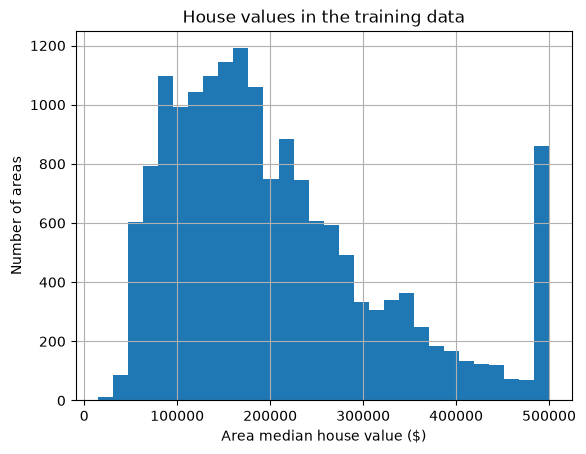

In [178]:
import matplotlib.pyplot as plt

train_data["median_house_value"].hist(bins=30)

plt.xlabel("Area median house value ($)")
plt.ylabel("Number of areas")
plt.title("House values in the training data")
plt.show()

In [179]:
train_data["median_house_value"].value_counts().head()

median_house_value
500001.0    786
137500.0     93
162500.0     89
112500.0     82
187500.0     73
Name: count, dtype: int64

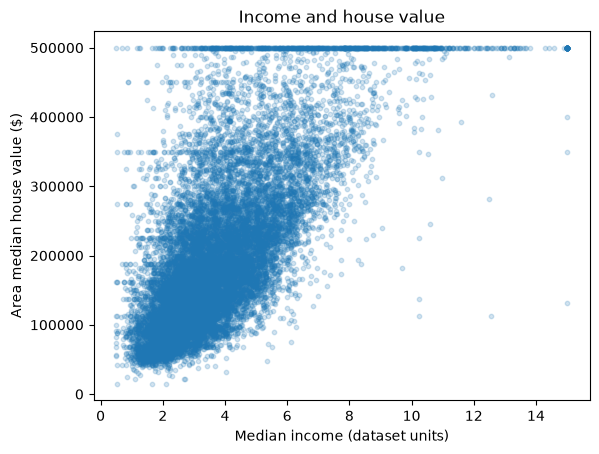

In [180]:
plt.scatter(
    train_data["median_income"],
    train_data["median_house_value"],
    alpha=0.2,
    s=10
)

plt.xlabel("Median income (dataset units)")
plt.ylabel("Area median house value ($)")
plt.title("Income and house value")
plt.show()

In [181]:
train_data["median_income"].corr(
    train_data["median_house_value"]
)

np.float64(0.6906466061467708)

In [182]:
train_data.corr(numeric_only=True)["median_house_value"].sort_values(
    ascending=False
)

median_house_value     1.000000
median_income          0.690647
rooms_per_household    0.158485
total_rooms            0.133989
housing_median_age     0.103706
households             0.063714
total_bedrooms         0.047980
population            -0.026032
longitude             -0.046349
latitude              -0.142983
Name: median_house_value, dtype: float64

In [183]:
train_data.groupby("ocean_proximity")["median_house_value"].median()

ocean_proximity
<1H OCEAN     215200.0
INLAND        109000.0
ISLAND        357350.0
NEAR BAY      234800.0
NEAR OCEAN    228000.0
Name: median_house_value, dtype: float64

In [184]:
train_data.groupby("ocean_proximity")["median_house_value"].agg(
    ["count", "median"]
)

,count,median
ocean_proximity,,
<1H OCEAN,7341,215200.0
INLAND,5227,109000.0
ISLAND,4,357350.0
NEAR BAY,1854,234800.0
NEAR OCEAN,2086,228000.0


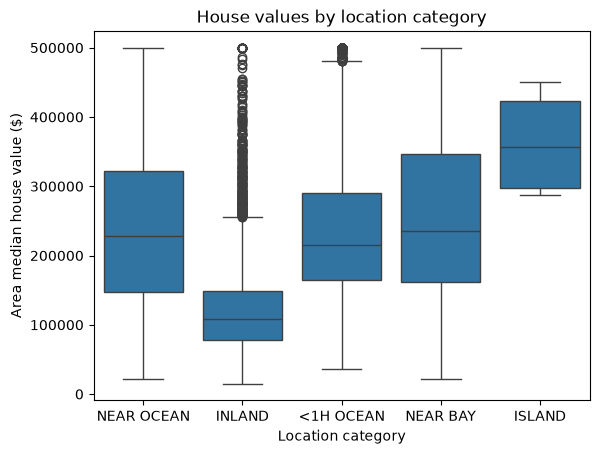

In [185]:
import seaborn as sns

sns.boxplot(
    data=train_data,
    x="ocean_proximity",
    y="median_house_value"
)

plt.xlabel("Location category")
plt.ylabel("Area median house value ($)")
plt.title("House values by location category")
plt.show()

In [186]:
train_data.isna().sum()

longitude              0
latitude               0
housing_median_age     0
total_rooms            0
total_bedrooms         0
population             0
households             0
median_income          0
median_house_value     0
ocean_proximity        0
rooms_per_household    0
dtype: int64

In [187]:
print("Full data:", housing.shape)
print("Training data:", train_data.shape)

print("Missing bedrooms in full data:",
      housing["total_bedrooms"].isna().sum())

print("Missing bedrooms in training data:",
      train_data["total_bedrooms"].isna().sum())

Full data: (20640, 11)
Training data: (16512, 11)
Missing bedrooms in full data: 207
Missing bedrooms in training data: 0


In [188]:
check_train, check_test = train_test_split(
    housing,
    test_size=0.2,
    random_state=42
)

print("Fresh training missing:",
      check_train["total_bedrooms"].isna().sum())

print("Fresh test missing:",
      check_test["total_bedrooms"].isna().sum())

Fresh training missing: 0
Fresh test missing: 207


In [189]:
housing.loc[
    housing["total_bedrooms"].isna()
].index

Index([  290,   341,   538,   563,   696,   738,  1097,  1350,  1456,  1493,
       ...
       19932, 19959, 20046, 20069, 20125, 20267, 20268, 20372, 20460, 20484],
      dtype='int64', length=207)

In [190]:
raw_check = pd.read_csv("data/housing.csv")

raw_train, raw_test = train_test_split(
    raw_check,
    test_size=0.2,
    random_state=42
)

print("Original CSV missing:",
      raw_check["total_bedrooms"].isna().sum())
print("Raw training missing:",
      raw_train["total_bedrooms"].isna().sum())
print("Raw test missing:",
      raw_test["total_bedrooms"].isna().sum())

Original CSV missing: 207
Raw training missing: 0
Raw test missing: 207


In [191]:
bedroom_median = train_data["total_bedrooms"].median()

print("Training bedroom median:", bedroom_median)

Training bedroom median: 437.0


In [192]:
example = pd.Series([120, None, 800])

example.fillna(bedroom_median)

0    120.0
1    437.0
2    800.0
dtype: float64

In [193]:
train_prepared = train_data.copy()
test_prepared = test_data.copy()

train_prepared["total_bedrooms"] = (
    train_prepared["total_bedrooms"].fillna(bedroom_median)
)

test_prepared["total_bedrooms"] = (
    test_prepared["total_bedrooms"].fillna(bedroom_median)
)

print("Training missing:",
      train_prepared["total_bedrooms"].isna().sum())
print("Test missing:",
      test_prepared["total_bedrooms"].isna().sum())

Training missing: 0
Test missing: 0


In [194]:
X_train = train_prepared.drop(columns=["median_house_value"])
y_train = train_prepared["median_house_value"]

print("Inputs:", X_train.shape)
print("Target:", y_train.shape)

Inputs: (16512, 10)
Target: (16512,)


In [195]:
example_categories = pd.DataFrame({
    "location": ["INLAND", "NEAR BAY", "INLAND"]
})

pd.get_dummies(example_categories, dtype=int)

,location_INLAND,location_NEAR BAY
0,1,0
1,0,1
2,1,0


In [196]:
X_train_encoded = pd.get_dummies(
    X_train,
    columns=["ocean_proximity"],
    dtype=int
)

print(X_train_encoded.shape)
X_train_encoded.head()

(16512, 14)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596,5.017657,0,0,0,0,1
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125,4.473545,0,0,0,0,1
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563,5.645833,0,0,0,0,1
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425,4.002817,0,0,0,0,1
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542,6.268421,0,1,0,0,0


In [197]:
X_test = test_prepared.drop(columns=["median_house_value"])
y_test = test_prepared["median_house_value"]

X_test_encoded = pd.get_dummies(
    X_test,
    columns=["ocean_proximity"],
    dtype=int
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Test inputs:", X_test_encoded.shape)
print("Columns match:",
      X_test_encoded.columns.equals(X_train_encoded.columns))

Test inputs: (4128, 14)
Columns match: True


In [198]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_encoded, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[-27888.63,-26644.72, 1111.58,...,117351.23,-24099.25,-15846.73]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['longitude','latitude','housing_median_age',...,'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY','ocean_proximity_NEAR OCEAN']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.349e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [199]:
sample_inputs = X_train_encoded.head()

sample_predictions = linear_model.predict(sample_inputs)

comparison = pd.DataFrame({
    "actual": y_train.head(),
    "predicted": sample_predictions
})

comparison["error"] = comparison["actual"] - comparison["predicted"]

comparison

,actual,predicted,error
14196,103000.0,189723.497214,-86723.497214
8267,382100.0,290805.247943,91294.752057
17445,172600.0,252908.313103,-80308.313103
14265,93400.0,146684.107676,-53284.107676
2271,96500.0,165940.837363,-69440.837363


In [200]:
from sklearn.metrics import mean_absolute_error

train_predictions = linear_model.predict(X_train_encoded)

train_mae = mean_absolute_error(y_train, train_predictions)

print("Training MAE:", train_mae)

Training MAE: 49586.743586646655


In [201]:
baseline_value = y_train.median()

baseline_predictions = [baseline_value] * len(y_train)

baseline_mae = mean_absolute_error(y_train, baseline_predictions)

print("Baseline prediction:", baseline_value)
print("Baseline training MAE:", baseline_mae)
print("Linear model training MAE:", train_mae)

Baseline prediction: 179850.0
Baseline training MAE: 88591.78712451551
Linear model training MAE: 49586.743586646655


In [202]:
import numpy as np

train_rmse = np.sqrt(
    np.mean((y_train - train_predictions) ** 2)
)

print("Training MAE:", train_mae)
print("Training RMSE:", train_rmse)

Training MAE: 49586.743586646655
Training RMSE: 68334.40727990535


In [203]:
from sklearn.metrics import r2_score

train_r2 = r2_score(y_train, train_predictions)

print("Training R²:", train_r2)

Training R²: 0.650683174133635


In [204]:
test_predictions = linear_model.predict(X_test_encoded)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(np.mean((y_test - test_predictions) ** 2))
test_r2 = r2_score(y_test, test_predictions)

baseline_test_mae = mean_absolute_error(
    y_test,
    [baseline_value] * len(y_test)
)

print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R²:", test_r2)
print("Baseline test MAE:", baseline_test_mae)

Test MAE: 50551.74903520472
Test RMSE: 69839.39490573353
Test R²: 0.6277848242961036
Baseline test MAE: 87403.99224806202


### First Linear Regression results
- Training MAE: $49,586.74
- Test MAE: $50,551.75
- Test RMSE: $69,839.39
- Test R²: 0.628
- Baseline test MAE: $87,403.99
- Model beats the baseline; training and test errors are close.
- Limitations: suspected target cap, rare island examples, and all
  missing-bedroom rows falling in this test split.

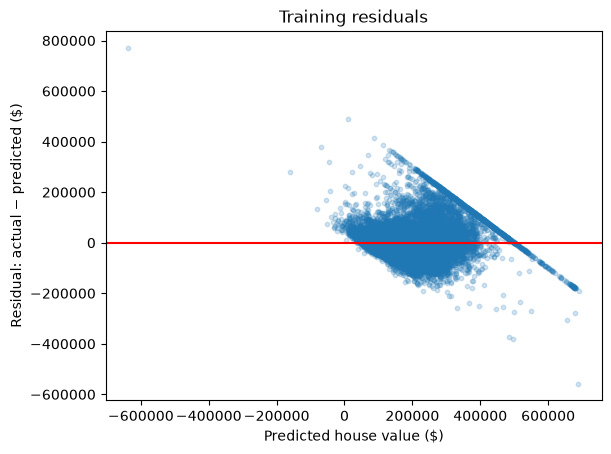

In [205]:
train_residuals = y_train - train_predictions

plt.scatter(train_predictions, train_residuals, alpha=0.2, s=10)
plt.axhline(0, color="red")

plt.xlabel("Predicted house value ($)")
plt.ylabel("Residual: actual − predicted ($)")
plt.title("Training residuals")
plt.show()

In [206]:
training_errors = pd.DataFrame({
    "actual": y_train,
    "predicted": train_predictions,
    "residual": train_residuals
})

training_errors.nsmallest(1, "predicted")

,actual,predicted,residual
15360,134400.0,-637278.169421,771678.169421


In [207]:
train_data.loc[[15360]]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household
15360,-117.42,33.35,14.0,25135.0,4819.0,35682.0,4769.0,2.5729,134400.0,<1H OCEAN,5.270497


In [208]:
coefficients = pd.Series(
    linear_model.coef_,
    index=X_train_encoded.columns
)

contributions = X_train_encoded.loc[15360] * coefficients

contributions.sort_values()

population                   -1.367682e+06
latitude                     -8.886013e+05
total_rooms                  -1.891576e+05
ocean_proximity_<1H OCEAN    -1.895861e+04
ocean_proximity_NEAR BAY     -0.000000e+00
ocean_proximity_ISLAND        0.000000e+00
ocean_proximity_INLAND       -0.000000e+00
ocean_proximity_NEAR OCEAN   -0.000000e+00
rooms_per_household           1.061161e+04
housing_median_age            1.556214e+04
median_income                 9.973991e+04
households                    3.645480e+05
total_bedrooms                4.112566e+05
longitude                     3.274682e+06
dtype: float64

In [209]:
print("Intercept:", linear_model.intercept_)

print("Reconstructed prediction:",
      linear_model.intercept_ + contributions.sum())

print("Model prediction:",
      linear_model.predict(X_train_encoded.loc[[15360]])[0])

Intercept: -2349279.753156485
Reconstructed prediction: -637278.1694205231
Model prediction: -637278.1694205231


In [210]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Fit inputs:", X_fit.shape)
print("Validation inputs:", X_valid.shape)

Fit inputs: (13209, 10)
Validation inputs: (3303, 10)


In [211]:
X_fit_encoded = pd.get_dummies(
    X_fit, columns=["ocean_proximity"], dtype=int
)

X_valid_encoded = pd.get_dummies(
    X_valid, columns=["ocean_proximity"], dtype=int
)

X_valid_encoded = X_valid_encoded.reindex(
    columns=X_fit_encoded.columns,
    fill_value=0
)

print("Fit:", X_fit_encoded.shape)
print("Validation:", X_valid_encoded.shape)
print("Columns match:",
      X_fit_encoded.columns.equals(X_valid_encoded.columns))

Fit: (13209, 14)
Validation: (3303, 14)
Columns match: True


In [212]:
reference_model = LinearRegression()
reference_model.fit(X_fit_encoded, y_fit)

reference_valid_predictions = reference_model.predict(X_valid_encoded)

reference_valid_mae = mean_absolute_error(
    y_valid, reference_valid_predictions
)

print("Reference validation MAE:", reference_valid_mae)

Reference validation MAE: 50926.75770101887


In [213]:
X_fit_candidate = X_fit_encoded.copy()
X_valid_candidate = X_valid_encoded.copy()

X_fit_candidate["people_per_household"] = (
    X_fit_candidate["population"] / X_fit_candidate["households"]
)

X_valid_candidate["people_per_household"] = (
    X_valid_candidate["population"] / X_valid_candidate["households"]
)

X_fit_candidate[
    ["population", "households", "people_per_household"]
].head()

,population,households,people_per_household
16490,873.0,258.0,3.383721
6090,3359.0,1267.0,2.651144
10973,1273.0,437.0,2.913043
17287,705.0,257.0,2.743191
12615,1857.0,739.0,2.512855


In [214]:
candidate_model = LinearRegression()
candidate_model.fit(X_fit_candidate, y_fit)

candidate_valid_predictions = candidate_model.predict(X_valid_candidate)

candidate_valid_mae = mean_absolute_error(
    y_valid, candidate_valid_predictions
)

print("Reference validation MAE:", reference_valid_mae)
print("Candidate validation MAE:", candidate_valid_mae)

Reference validation MAE: 50926.75770101887
Candidate validation MAE: 51003.473859563106


### Feature experiment: people_per_household
- Added population / households alongside existing inputs.
- Reference validation MAE: $50,926.76
- Candidate validation MAE: $51,003.47
- No improvement on this validation split; retain the reference for now.

In [215]:
X_fit["total_rooms"].corr(X_fit["households"])

np.float64(0.9209368583848586)

In [216]:
X_fit_reduced = X_fit_encoded.drop(columns=["total_rooms"])
X_valid_reduced = X_valid_encoded.drop(columns=["total_rooms"])

reduced_model = LinearRegression()
reduced_model.fit(X_fit_reduced, y_fit)

reduced_predictions = reduced_model.predict(X_valid_reduced)

reduced_valid_mae = mean_absolute_error(y_valid, reduced_predictions)

print("Reference validation MAE:", reference_valid_mae)
print("Without total_rooms:", reduced_valid_mae)

Reference validation MAE: 50926.75770101887
Without total_rooms: 51180.80115262332


### Feature experiment: remove total_rooms
- Correlation with households: 0.921.
- Validation MAE increased from $50,926.76 to $51,180.80.
- Retain total_rooms for now; this split did not support removing it.

In [217]:
reference_column = "ocean_proximity_<1H OCEAN"

X_fit_reference = X_fit_encoded.drop(columns=[reference_column])
X_valid_reference = X_valid_encoded.drop(columns=[reference_column])

reference_category_model = LinearRegression()
reference_category_model.fit(X_fit_reference, y_fit)

reference_category_predictions = reference_category_model.predict(
    X_valid_reference
)

print("Validation MAE:",
      mean_absolute_error(y_valid, reference_category_predictions))

print("Largest prediction difference:",
      np.max(np.abs(
          reference_category_predictions - reference_valid_predictions
      )))

Validation MAE: 50926.757701019174
Largest prediction difference: 1.3597309589385986e-07


In [218]:
reference_coefficients = pd.Series(
    reference_category_model.coef_,
    index=X_fit_reference.columns
)

reference_coefficients[
    reference_coefficients.index.str.startswith("ocean_proximity_")
]

ocean_proximity_INLAND        -37929.307643
ocean_proximity_ISLAND        211884.032055
ocean_proximity_NEAR BAY       -4858.979614
ocean_proximity_NEAR OCEAN      4820.454661
dtype: float64

In [219]:
reference_coefficients["median_income"]

np.float64(39081.436345906695)

### Coefficient interpretation
- Income coefficient: +$39,081.44 per dataset unit,
  holding other inputs fixed.
- Location coefficients compare against <1H OCEAN.
- Positive coefficients raise predictions; negative ones lower them.
- Coefficients describe model associations, not causal effects.
- Correlated inputs can make individual coefficients hard to interpret.

In [220]:
numeric_columns = X_fit.select_dtypes(include="number").columns.tolist()
categorical_columns = ["ocean_proximity"]

print("Numerical:", numeric_columns)
print("Categorical:", categorical_columns)

Numerical: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household']
Categorical: ['ocean_proximity']


In [221]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer([
    ("numbers", SimpleImputer(strategy="median"), numeric_columns),
    ("categories", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_columns)
])

In [222]:
from sklearn.pipeline import Pipeline

linear_pipeline = Pipeline([
    ("prepare", preprocessor),
    ("model", LinearRegression())
])

linear_pipeline.fit(X_fit, y_fit)

pipeline_valid_predictions = linear_pipeline.predict(X_valid)

print("Pipeline validation MAE:",
      mean_absolute_error(y_valid, pipeline_valid_predictions))

Pipeline validation MAE: 50926.75770102392


In [223]:
missing_example = X_valid.head(1).copy()
missing_example["total_bedrooms"] = np.nan

linear_pipeline.predict(missing_example)

array([167574.97895933])

In [224]:
learned_medians = pd.Series(
    linear_pipeline.named_steps["prepare"]
        .named_transformers_["numbers"].statistics_,
    index=numeric_columns
)

learned_medians

longitude              -118.510000
latitude                 34.270000
housing_median_age       29.000000
total_rooms            2128.000000
total_bedrooms          437.000000
population             1168.000000
households              411.000000
median_income             3.546100
rooms_per_household       5.226804
dtype: float64

In [225]:
prepared_example = linear_pipeline.named_steps["prepare"].transform(
    missing_example
)

bedroom_position = numeric_columns.index("total_bedrooms")

print("Filled bedroom value:",
      prepared_example[0, bedroom_position])

Filled bedroom value: 437.0


In [226]:
def add_room_ratio(data):
    result = data.copy()

    result["rooms_per_household"] = (
        result["total_rooms"] / result["households"]
    )

    return result

raw_example = X_fit.head(2).drop(columns=["rooms_per_household"])

add_room_ratio(raw_example)[
    ["total_rooms", "households", "rooms_per_household"]
]

,total_rooms,households,rooms_per_household
16490,1683.0,258.0,6.523256
6090,6409.0,1267.0,5.058406


In [227]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone

X_fit_raw = X_fit.drop(columns=["rooms_per_household"])
X_valid_raw = X_valid.drop(columns=["rooms_per_household"])

full_pipeline = Pipeline([
    ("features", FunctionTransformer(add_room_ratio, validate=False)),
    ("prepare", clone(preprocessor)),
    ("model", LinearRegression())
])

full_pipeline.fit(X_fit_raw, y_fit)

full_valid_predictions = full_pipeline.predict(X_valid_raw)

print("Validation MAE:",
      mean_absolute_error(y_valid, full_valid_predictions))

Validation MAE: 50926.75770102392


In [228]:
from sklearn.model_selection import KFold, cross_val_score

X_train_raw = train_data.drop(
    columns=["median_house_value", "rooms_per_household"]
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_mae = -cross_val_score(
    full_pipeline,
    X_train_raw,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

print("MAE for each fold:", cv_mae)
print("Average MAE:", cv_mae.mean())
print("Standard deviation:", cv_mae.std())

MAE for each fold: [50926.75770102 49195.4454748  48136.90985165 50424.89472789
 49610.48141864]
Average MAE: 49658.89783479956
Standard deviation: 972.3990477975784


### Five-fold cross-validation
- Full pipeline evaluated on training data only.
- Average MAE: $49,658.90
- Standard deviation across fold MAEs: $972.40
- Each fold learns its own preparation settings and model.
- Scores describe random splits of these areas, not performance
  on future years or entirely new regions.

In [229]:
required_columns = X_train_raw.columns

incoming_example = X_valid_raw.head(2).copy()

missing_columns = required_columns.difference(incoming_example.columns)

print("Missing columns:", missing_columns.tolist())

Missing columns: []


In [230]:
print("Rows with households ≤ 0:",
      (incoming_example["households"] <= 0).sum())


Rows with households ≤ 0: 0


In [231]:
print("Missing household values:",
      incoming_example["households"].isna().sum())

Missing household values: 0


In [232]:
def add_room_ratio(data):
    result = data.copy()

    valid_households = result["households"].where(
        result["households"] > 0
    )

    result["rooms_per_household"] = (
        result["total_rooms"] / valid_households
    )

    return result

zero_example = incoming_example.head(1).copy()
zero_example["households"] = 0

add_room_ratio(zero_example)[
    ["households", "rooms_per_household"]
]


,households,rooms_per_household
2071,0,NaN


In [233]:
safe_pipeline = Pipeline([
    ("features", FunctionTransformer(add_room_ratio, validate=False)),
    ("prepare", clone(preprocessor)),
    ("model", LinearRegression())
])

safe_pipeline.fit(X_fit_raw, y_fit)

safe_valid_predictions = safe_pipeline.predict(X_valid_raw)

print("Validation MAE:",
      mean_absolute_error(y_valid, safe_valid_predictions))

Validation MAE: 50926.75770102392


### Reusable pipeline
- Creates rooms_per_household.
- Uses fit-derived medians for missing numerical values.
- Encodes location categories consistently.
- Applies Linear Regression.
- Non-positive or missing households produce a missing ratio.
- Invalid input records still need review.

In [234]:
incoming_example["ocean_proximity"].value_counts()

ocean_proximity
INLAND        1
NEAR OCEAN    1
Name: count, dtype: int64

In [235]:
incoming_predictions = safe_pipeline.predict(incoming_example)

pd.DataFrame({
    "ocean_proximity": incoming_example["ocean_proximity"],
    "predicted_house_value": incoming_predictions
})

,ocean_proximity,predicted_house_value
2071,INLAND,145763.550704
2612,NEAR OCEAN,133067.593385


In [236]:
incoming_comparison = pd.DataFrame({
    "actual": y_valid.loc[incoming_example.index],
    "predicted": incoming_predictions
})

incoming_comparison["error"] = (
    incoming_comparison["actual"] - incoming_comparison["predicted"]
)

incoming_comparison

,actual,predicted,error
2071,96700.0,145763.550704,-49063.550704
2612,75500.0,133067.593385,-57567.593385


In [237]:
validation_errors = y_valid - safe_valid_predictions

print("Average signed error:", validation_errors.mean())

Average signed error: -1893.1150840984183


In [238]:
validation_report = pd.DataFrame({
    "category": X_valid_raw["ocean_proximity"],
    "error": validation_errors,
    "absolute_error": validation_errors.abs()
})

validation_report.groupby("category").agg(
    count=("error", "count"),
    mean_error=("error", "mean"),
    mae=("absolute_error", "mean")
)

,count,mean_error,mae
category,,,
<1H OCEAN,1493,-101.288040,51803.841631
INLAND,1010,-2404.695031,36002.574687
ISLAND,2,-150823.663280,150823.663280
NEAR BAY,363,188.262943,73163.991705
NEAR OCEAN,435,-7907.324640,63552.111225


### Validation error analysis
- Overall signed error: −$1,893; MAE: $50,927.
- Near-zero signed error can hide large individual mistakes.
- Errors differ by location category.
- Island validation has only 2 examples; conclusions are limited.
- Group MAEs also reflect differences in price ranges.

In [239]:
from pathlib import Path

print("Python is looking from:", Path.cwd())
print("CSV exists here:", Path("data/housing.csv").exists())

Python is looking from: c:\Users\anjal\OneDrive\Documents\regression-learning
CSV exists here: True


In [240]:
from pathlib import Path

working_folder = Path.cwd()
csv_path = Path("data/housing.csv")
file_exists = csv_path.exists()

print("Python is looking from:", working_folder)
print("CSV exists here:", file_exists)

Python is looking from: c:\Users\anjal\OneDrive\Documents\regression-learning
CSV exists here: True
